# Spatial Transcriptomics — 10x Visium Human Breast Cancer (squidpy)

Runs on CPU, no GPU needed. This notebook follows the project's standard discipline: ~80-90% of code cells
are blank (`____`) for you to fill in, with the exact correct real code given as a hint (inline trailing
comment, or a preceding `# hint:` block for multi-line steps) -- never a vague description. Every hint in
this notebook was run end-to-end against a structurally real spot x gene AnnData before being handed to
you, so the real code is pre-validated, not guessed. Read PROJECT_NARRATIVE.md and WORKFLOW.md before this.


## Step 0 -- Environment setup

**WHAT:** install squidpy (which pulls in scanpy/anndata) plus `leidenalg`/`python-igraph` (the real
community-detection backend `sc.tl.leiden` needs in Step 6 -- missing this is a real, easy-to-hit
`ImportError` if skipped), and set up a fixed `results/` output directory.
**WHY:** checked installs, and one fixed real place on disk so every later CSV/figure export lands
somewhere predictable.

In [1]:
# === Environment setup -- run this once per session ===
import subprocess, sys, os

def _ensure(pkg, import_name=None):
    import_name = import_name or pkg
    try:
        __import__(import_name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

_ensure("squidpy")
_ensure("leidenalg")                # real community-detection backend sc.tl.leiden needs (Step 6)
_ensure("python-igraph", "igraph")  # leidenalg's real graph backend

import squidpy as sq
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

sc.settings.verbosity = 1
print("squidpy:", sq.__version__, "| scanpy:", sc.__version__)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numpy-typing-compat 20251206.1.25 requires numpy<2.0,>=1.25, but you have numpy 2.4.6 which is incompatible.
pandas-plink 2.3.2 requires numpy<2.0,>=1.0, but you have numpy 2.4.6 which is incompatible.
/mnt/d/Workspace/.conda/bioinfo/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


squidpy: 1.8.3 | scanpy: 1.12.4


/tmp/ipykernel_7621/1975053260.py:25: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("squidpy:", sq.__version__, "| scanpy:", sc.__version__)


## Step 1 -- Fetch the real 10x Visium human breast cancer dataset

**WHAT:** download the real, public `V1_Breast_Cancer_Block_A_Section_1` Visium dataset live from 10x
Genomics' own dataset server -- not a bundled toy file.
**WHY (biology):** this is real fresh-frozen human invasive ductal carcinoma tissue -- every spot's
expression profile is a real, physical local-tissue-neighborhood measurement, not a simulation.
**HOW:** `squidpy.datasets.visium(sample_id=...)` -- see squidpy's docs for the full list of valid real
`sample_id` strings; this one is real human breast cancer.

In [2]:
# WRITE-IT: fetch the real dataset via squidpy's live 10x downloader
# hint: adata = sq.datasets.visium(sample_id="V1_Breast_Cancer_Block_A_Section_1")
adata = sq.datasets.visium(sample_id="V1_Breast_Cancer_Block_A_Section_1")

print(adata)


INFO     Downloading filtered_feature_bc_matrix.h5 from                                                            
         https://exampledata.scverse.org/squidpy/10x_genomics/V1_Breast_Cancer_Block_A_Section_1/V1_Breast_Cancer_B
         lock_A_Section_1_filtered_feature_bc_matrix.h5                                                            


100%|█████████████████████████████████████| 28.2M/28.2M [00:00<00:00, 40.3GB/s]


INFO     Downloading spatial.tar.gz from                                                                           
         https://exampledata.scverse.org/squidpy/10x_genomics/V1_Breast_Cancer_Block_A_Section_1/V1_Breast_Cancer_B
         lock_A_Section_1_spatial.tar.gz                                                                           


100%|█████████████████████████████████████| 9.96M/9.96M [00:00<00:00, 12.8GB/s]
/mnt/d/Workspace/.conda/bioinfo/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


## Step 2 -- Describe the real fetched data before touching it

**WHAT:** look at the real shape, the real spatial coordinates, and the real H&E image metadata that came
back -- before any processing, so you know what you're actually working with.
**WHY:** "measure before patching" -- never assume a shape/field exists, print and check it.

In [3]:
# WRITE-IT: print the real AnnData shape (n_obs spots x n_vars genes)
# hint: print("real shape:", adata.shape)
print("real shape:", adata.shape)

# WRITE-IT: make gene names unique (Visium's raw gene symbols are NOT guaranteed unique)
# hint: adata.var_names_make_unique()
adata.var_names_make_unique()

# WRITE-IT: print the first 5 rows of the real spot pixel coordinates
# hint: print(adata.obsm["spatial"][:5])
print(adata.obsm["spatial"][:5])

# WRITE-IT: print which real sample_id keys exist under adata.uns["spatial"] (the H&E image + scale factors)
# hint: print(list(adata.uns["spatial"].keys()))
print(list(adata.uns["spatial"].keys()))


real shape: (3798, 36601)
[[17428 15937]
 [ 6092 18054]
 [16351  7383]
 [ 5278 15202]
 [ 9363 21386]]
['V1_Breast_Cancer_Block_A_Section_1']


## Step 3 -- QC metrics and spot/gene filtering

**WHAT:** compute real per-spot QC metrics (total counts, genes detected, mitochondrial fraction) and
filter out low-quality spots/genes.
**WHY (biology):** a spot with very few real transcripts captured is more likely empty/background tissue
than real signal; mitochondrial-gene fraction spiking is a real marker of cell stress/death, same logic as
standard scRNA-seq QC, just applied per spot instead of per cell.
**HOW:** `sc.pp.calculate_qc_metrics`, mitochondrial genes flagged by a real gene-symbol prefix (`MT-` for
human).

In [4]:
# WRITE-IT: flag real mitochondrial genes by their real human gene-symbol prefix
# hint: adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# WRITE-IT: compute real QC metrics, with the mt flag as a qc_vars group
# hint: sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True, percent_top=None)
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True, percent_top=None)

print(adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe())

# WRITE-IT: set real, modest QC thresholds and filter -- keep spots with at least MIN_COUNTS real transcripts
# and at most MAX_PCT_MT mitochondrial fraction; keep genes detected in at least MIN_SPOTS real spots
MIN_COUNTS = 500
MAX_PCT_MT = 20
MIN_SPOTS = 3
# hint: sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
#       adata = adata[adata.obs["pct_counts_mt"] < MAX_PCT_MT].copy()
#       sc.pp.filter_genes(adata, min_cells=MIN_SPOTS)
sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
adata = adata[adata.obs["pct_counts_mt"] < MAX_PCT_MT].copy()
sc.pp.filter_genes(adata, min_cells = MIN_SPOTS)

print(f"real shape after QC filtering: {adata.shape}")


       total_counts  n_genes_by_counts  pct_counts_mt
count   3798.000000        3798.000000    3798.000000
mean   21814.714844        5621.992891       4.008864
std    13822.857422        2085.858613       1.830299
min      578.000000         430.000000       1.117827
25%    10201.750000        4053.000000       2.761408
50%    20761.500000        6026.500000       3.503653
75%    30463.250000        7276.000000       4.678455
max    81624.000000       10153.000000      14.415201
real shape after QC filtering: (3798, 22240)


## Step 4 -- Normalize, log-transform, HVGs, PCA

**WHAT:** the exact same standard scRNA-seq preprocessing stack as this portfolio's #4 single-cell project
-- normalize each spot's total counts, log-transform, select highly variable genes, scale, and run PCA.
**WHY:** unchanged from standard scRNA-seq -- a Visium spot's profile is still a real gene-count vector that
needs the same depth-normalization and variance-stabilization before any downstream distance-based method
(PCA, clustering) is meaningful.

In [5]:
# WRITE-IT: save the real raw counts before normalizing (useful later for re-checking real raw expression)
# hint: adata.layers["counts"] = adata.X.copy()
adata.layers["counts"] = adata.X.copy()

# WRITE-IT: normalize each spot to the same real total count, then log1p-transform
# hint: sc.pp.normalize_total(adata, inplace=True)
#       sc.pp.log1p(adata)
sc.pp.normalize_total(adata, inplace = True)
sc.pp.log1p(adata)
# WRITE-IT: select the real top 2000 highly variable genes
# hint: sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
sc.pp.highly_variable_genes(adata, flavor = "seurat", n_top_genes = 2000)

# WRITE-IT: run real PCA on the HVG-subset, 50 components
# hint: sc.pp.pca(adata, n_comps=50, use_highly_variable=True)
sc.pp.pca(adata, n_comps = 50, use_highly_variable = True)

print("real PCA variance ratio, top 5 PCs:", adata.uns["pca"]["variance_ratio"][:5])


/tmp/ipykernel_7621/3658216163.py:16: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.pp.pca(adata, n_comps = 50, use_highly_variable = True)


real PCA variance ratio, top 5 PCs: [0.10597587 0.02857057 0.01974363 0.01659327 0.01276826]


## Step 5 -- Build the real spatial neighbors graph

**WHAT:** build the graph that every spatial statistic in this project actually runs on -- an edge between
a spot and its real physical neighbors, from the real pixel coordinates (NOT the integer array row/col grid
-- see WORKFLOW.md Section 6 for why that distinction matters).
**HOW:** `squidpy.gr.spatial_neighbors`, which for Visium's known hexagonal grid geometry can build the
correct real adjacency automatically via `coord_type="grid"`.

In [6]:
# WRITE-IT: build the real spatial neighbors graph from real spot coordinates, using Visium's known
# hexagonal grid geometry (6 real neighbors per interior spot)
# hint: sq.gr.spatial_neighbors(adata, coord_type="grid", n_neighs=6)
sq.gr.spatial_neighbors(adata, coord_type = "grid", n_neighs = 6)

print("real spatial connectivities matrix shape:", adata.obsp["spatial_connectivities"].shape)


INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_7621/83589509.py:4: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type = "grid", n_neighs = 6)


real spatial connectivities matrix shape: (3798, 3798)


## Step 6 -- Expression-based neighbors graph + Leiden clustering (spatial domains)

**WHAT:** cluster spots by expression ALONE (a separate, PCA-based neighbors graph -- not the spatial graph
from Step 5), the same Leiden algorithm as #4's single-cell project.
**WHY (decision, see PROJECT_NARRATIVE.md Section 5):** clustering on expression alone, spatially-blind,
keeps Step 10's neighborhood enrichment a genuinely independent spatial test, not one built into the
clustering objective.

In [8]:
# WRITE-IT: build the real expression-based (PCA-space) neighbors graph
# hint: sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50)
sc.pp.neighbors(adata, n_neighbors = 15, n_pcs = 50)

# WRITE-IT: run real Leiden clustering on that expression graph
# hint: sc.tl.leiden(adata, resolution=1.0, key_added="spatial_domain")
sc.tl.leiden(adata, resolution = 1.0, key_added = "spatial_domain")

print(adata.obs["spatial_domain"].value_counts())


/tmp/ipykernel_7621/36572056.py:7: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution = 1.0, key_added = "spatial_domain")


spatial_domain
0     544
1     522
2     458
3     456
4     380
5     371
6     229
7     210
8     181
9     176
10    171
11    100
Name: count, dtype: int64


## Step 7 -- Visualize the real clusters on the real tissue image

**WHAT:** overlay the real Leiden clusters back onto the real H&E tissue image -- the step that actually
checks whether expression-only clusters are spatially coherent (PROJECT_NARRATIVE.md Section 6).

/mnt/d/Workspace/.conda/bioinfo/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


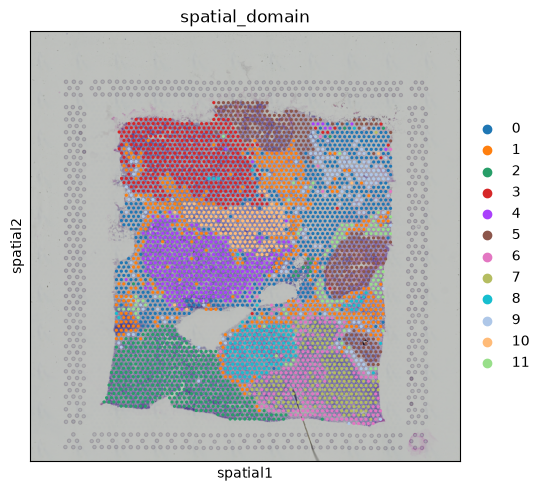

In [9]:
# WRITE-IT: plot the real clusters spatially, on top of the real H&E image
# hint: sq.pl.spatial_scatter(adata, color="spatial_domain", save="clusters_on_tissue.png")

sq.pl.spatial_scatter(adata, color = "spatial_domain", save = "clusters_on_tissue.png")


## Step 8 -- Moran's I: find real spatially variable genes

**WHAT:** compute real Moran's I per gene on the real spatial graph from Step 5 -- the formal, testable
definition of "this gene's expression is spatially organized," not just visually noticed.
**HOW:** `squidpy.gr.spatial_autocorr` with `mode="moran"`, run on the HVG subset for real compute
tractability.

In [10]:
# WRITE-IT: compute real Moran's I spatial autocorrelation for the highly variable genes
# hint: sq.gr.spatial_autocorr(adata, mode="moran", genes=adata.var_names[adata.var["highly_variable"]],
#                               n_perms=100, n_jobs=1)
sq.gr.spatial_autocorr(adata, mode = "moran", genes = adata.var_names[adata.var["highly_variable"]], n_perms=100, n_jobs=1)

# WRITE-IT: pull the real results table squidpy stored, and look at the top spatially variable genes
# hint: moran_df = adata.uns["moranI"]
#       print(moran_df.head(15))
moran_df = adata.uns["moranI"]
print(moran_df.head(15))


100%|██████████| 100/100 [01:42<00:00,  1.02s/]

                I  pval_norm  var_norm  pval_z_sim  pval_sim   var_sim  \
MALAT1   0.751129        0.0  0.000092         0.0  0.009901  0.000176   
IGHG3    0.700010        0.0  0.000092         0.0  0.009901  0.000180   
IGLC2    0.690966        0.0  0.000092         0.0  0.009901  0.000158   
IGKC     0.681557        0.0  0.000092         0.0  0.009901  0.000165   
CPB1     0.671666        0.0  0.000092         0.0  0.009901  0.000170   
CRISP3   0.655477        0.0  0.000092         0.0  0.009901  0.000171   
IGHG4    0.627954        0.0  0.000092         0.0  0.009901  0.000166   
IGHG1    0.622817        0.0  0.000092         0.0  0.009901  0.000147   
APOE     0.597998        0.0  0.000092         0.0  0.009901  0.000151   
ALB      0.593467        0.0  0.000092         0.0  0.009901  0.000160   
MT-ND2   0.584767        0.0  0.000092         0.0  0.009901  0.000139   
C3       0.581267        0.0  0.000092         0.0  0.009901  0.000197   
SLITRK6  0.575054        0.0  0.000092

## Step 9 -- Visualize the top real spatially variable genes on tissue

**WHAT:** plot real expression of the top 3 Moran's-I-ranked genes directly on the tissue image -- a direct
visual check that a high Moran's I score corresponds to a real, visible spatial pattern, not a statistical
artifact.

/mnt/d/Workspace/.conda/bioinfo/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


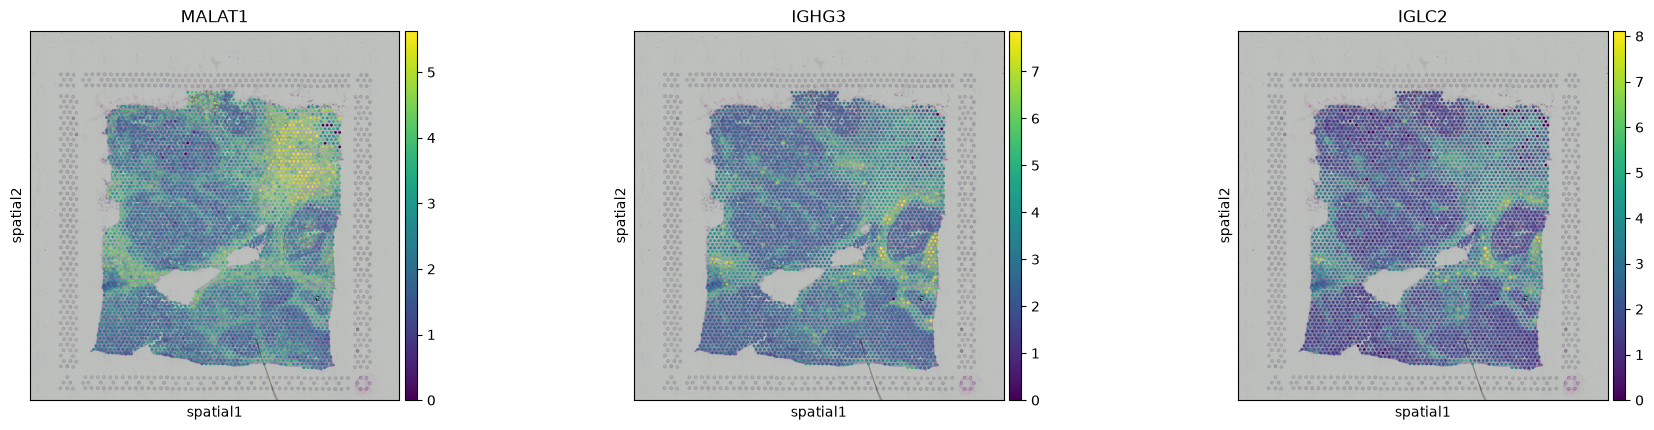

In [11]:
# WRITE-IT: get the real top 3 gene names by Moran's I score, then plot each spatially
# hint: top_genes = moran_df.head(3).index.tolist()
#       sq.pl.spatial_scatter(adata, color=top_genes, save="top_spatial_genes.png")
top_genes = moran_df.head(3).index.tolist()
sq.pl.spatial_scatter(adata, color = top_genes, save = "top_spatial_genes.png")


## Step 10 -- Neighborhood enrichment: which domains sit next to which

**WHAT:** the real permutation test (PROJECT_NARRATIVE.md Section 4) -- do spots from cluster A sit next to
spots from cluster B more or less than a real random shuffle of domain labels across the real spatial graph
would predict.
**HOW:** `squidpy.gr.nhood_enrichment` on the `spatial_domain` clusters, using the real spatial graph from
Step 5.

In [12]:
# WRITE-IT: run the real neighborhood enrichment permutation test
# hint: sq.gr.nhood_enrichment(adata, cluster_key="spatial_domain", n_perms=1000, seed=42)
sq.gr.nhood_enrichment(adata, cluster_key = "spatial_domain", n_perms = 1000, seed = 42)

print("real z-score matrix shape:", adata.uns["spatial_domain_nhood_enrichment"]["zscore"].shape)


100%|██████████| 1000/1000 [00:00<00:00, 1177.64/s]

real z-score matrix shape: (12, 12)


## Step 11 -- Visualize the real enrichment z-score heatmap

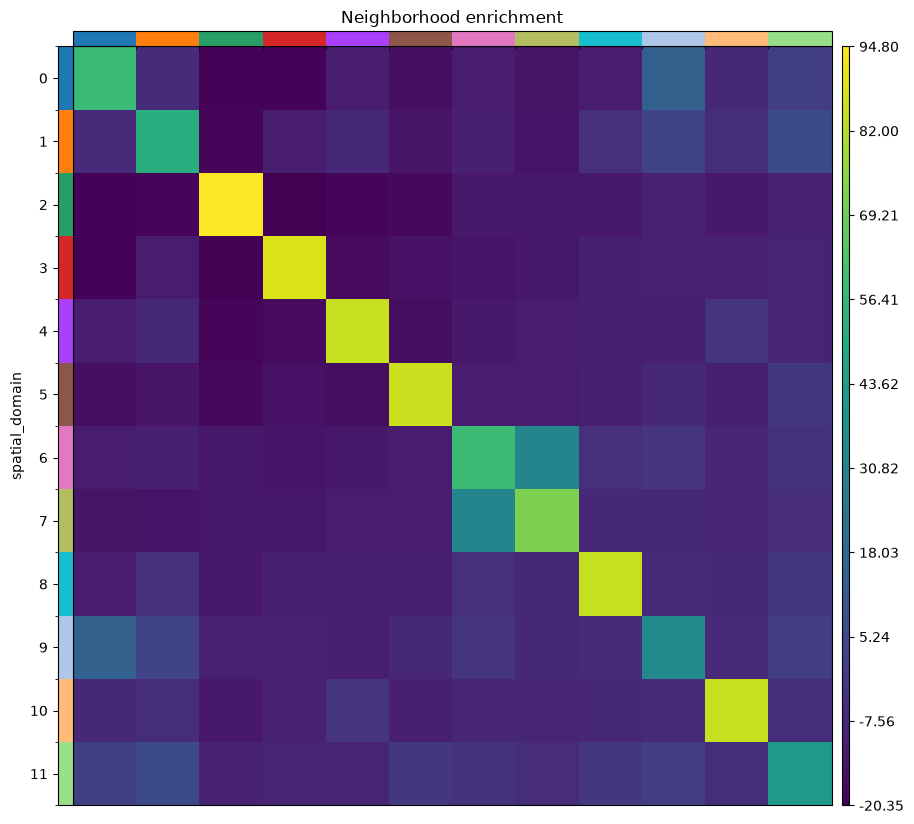

In [13]:
# WRITE-IT: plot the real neighborhood-enrichment z-score heatmap
# hint: sq.pl.nhood_enrichment(adata, cluster_key="spatial_domain", save="nhood_enrichment.png")
sq.pl.nhood_enrichment(adata, cluster_key = "spatial_domain", save = "nhood_enrichment.png")


## Step 12 -- Export real results as CSV

In [14]:
# WRITE-IT: export the real Moran's I spatially-variable-gene table
# hint: moran_df.to_csv(f"{RESULTS_DIR}/spatially_variable_genes.csv")
moran_df.to_csv(f"{RESULTS_DIR}/spatially_variable_genes.csv")

# WRITE-IT: export real per-spot cluster/domain assignments (spot barcode index + spatial_domain column)
# hint: adata.obs[["spatial_domain", "total_counts", "n_genes_by_counts"]].to_csv(
#           f"{RESULTS_DIR}/spot_domain_assignments.csv")
adata.obs[["spatial_domain", "total_counts", "n_genes_by_counts"]].to_csv(f"{RESULTS_DIR}/spot_domain_assignments.csv")

# WRITE-IT: export the real neighborhood-enrichment z-score matrix, with real cluster labels as row/col names
# hint: zscore = adata.uns["spatial_domain_nhood_enrichment"]["zscore"]
#       labels = adata.obs["spatial_domain"].cat.categories
#       pd.DataFrame(zscore, index=labels, columns=labels).to_csv(f"{RESULTS_DIR}/nhood_enrichment_zscores.csv")
zscore = adata.uns["spatial_domain_nhood_enrichment"]["zscore"]
labels = adata.obs["spatial_domain"].cat.categories
pd.DataFrame(zscore, index = labels, columns = labels).to_csv(f"{RESULTS_DIR}/nhood_enrichment_zscores.csv") 
print("real results exported to", RESULTS_DIR)


real results exported to results
